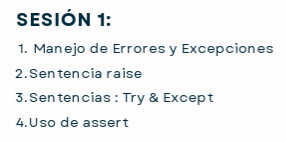

In [12]:
# Errores : Son fallas que impiden que el codigo se ejecute o que se produzcan resultados incorrecto
# Excepcion : Es un evento detectable en tiempo de ejecucion que interrumpe el flujo normal
# del programa, pero que pueden ser capturados y manejados.

# Tipos de Errores

* Errores de sintaxis (SyntaxError)
* Errores logicos (errores semanticos)
* Errores en tiempo de ejecucion (que se manifiestan como excepciones )

In [ ]:
# Ejemplo de un error de sintaxis
if 3.14157 > 1.2
    print("Una aproximacion de pi es mayor que 1.2")

In [ ]:
# Correcion
# Ejemplo de un error de sintaxis
if 3.14157 > 1.2:
    print("Una aproximacion de pi es mayor que 1.2")

In [ ]:
# Otro ejemplo de un error de sintaxis
a = 23
b = 12
c = 9
d = 3.21
resultado = (a+b * (c*d)
print(resultado)

In [ ]:
# Correccion
a = 23
b = 12
c = 9
d = 3.21
resultado = (a+b * (c*d))
print(resultado)

In [ ]:
# Otro ejemplo de error de sintaxis
def = 10

In [ ]:
# Obtengamos la lista de palabras reservadas
help("keywords")

In [ ]:
# Indentacion inconsistente
if True:
print("Hola")
    print("Mundo")

In [ ]:
# Error logico
def promedio(lista):
    suma = 0.0
    for x in lista:
        suma -= x
    return suma/len(lista)-1

In [ ]:
promedio([12,14,16])

In [ ]:
# Otro error logico
edad = 16
if edad >18:
    print("No se puede participar en las elecciones generales")
else:
    print("Puede participar en las elecciones generales ")

In [ ]:
# Otro error logico
# Deseo implementar una funcion que duplique cada cada elemento de un objeto de tipo lista
def duplicar(vector):
    return vector*2

In [ ]:
original = [1,2,3]
resultado = duplicar(original)
resultado

In [ ]:
# Errores en tiempo de ejecucion -> Excepciones

In [ ]:
# Veamos otro ejemplito
x = 10
y = 0
z = x/y

In [ ]:
# Veamos otro ejemplito mas
# Deseo abrir un archivo de texto : datos.csv
with open("datos.csv", "r") as f:
    contenido = f.read()

In [ ]:
# Otro ejemplito usando diccionarios
datos = {"nombre":"Rosa", "año_nacimiento":1958}
vaR_ciudad = datos["ciudad"]

In [ ]:
# Otro ejemplito
listanotas = [12,9,3,8,11,17]
listanotas[6]

In [ ]:
# otro ejemplito
nota1 = int("veinte")

# Manejo / Administracion de Excepciones

In [ ]:
help(ValueError)

In [ ]:
help(Exception)

In [ ]:
help(ZeroDivisionError)

In [ ]:
help(ArithmeticError)

In [ ]:
help(BaseException)

In [ ]:
# Obtener las excepciones que python provee
dir(locals()["__builtins__"])

In [7]:
# Problema : Buscamos obtener todas las excepciones que python provee

# Cargar el modulo builtins
import builtins

# Obtengamos los atributos del modulo builtins
builtin_attr = dir(builtins)

# Filtrar aquellas clases que provee builtins y que ademas sean clases hija (subclases)
# de la clase BaseException : Utilicemos/construyamos una list comprehension
exceptions = [name for name in builtin_attr
 if isinstance(getattr(builtins, name), type)
 and issubclass(getattr(builtins, name), BaseException)
 ]


In [ ]:
help(isinstance)

In [9]:
# NUmero de excepciones que provee python
len(exceptions)

72

In [ ]:
# Documentacion
help(FloatingPointError)

In [11]:
# Fija para la primera evaluacion : Leer la documentacion de
# cada una de las 71 excepciones que python provee.

# Bloque `try-except`



In [ ]:
# Ejemplito1 : Evitar que una operacion de naturaleza aritmetica detenga nuestro codigo
def dividir(a,b):
    try:
        resultado = a/b
        return resultado
    except ZeroDivisionError:
        print("ERROR : El denominador no debe ser cero")
        return None

In [ ]:
# primera prueba
dividir(10,2)

In [ ]:
# segunda prueba
dividir(10,0)

In [ ]:
# Ejemplito2 : Manejo de entrada del usuario
entrada = input("Ingrese un numero entero : ")

try:
    entrada = int(entrada)
    # Luego ya puedo realizar alguna operaciones
    print(f"El doble del input es {entrada*2}")
except ValueError:
    print("Ingreso Invalido")

In [ ]:
# Ejemplito3 : Lectura de datos
def procesar_archivo(ruta):
    try:
        # Cargamos el archivo en memoria ram
        with open(ruta, "r", encoding="utf-8-sig") as f:
            lineas = f.readlines()

        datos = []
        for i , linea in enumerate(lineas, start= 1):
            linea = linea.strip()
            if not linea:
                continue

            # Dividir por comas (o tabs)
            campos = linea.split(",")

            # Validemos que cada fila tiene 5 columnas
            if len(campos) !=5:
                print("NO hay 5 columnas")
                raise ValueError(f"Linea {i} no tiene 5 columns ")

            # Convertir cada elemento de la variable campos a un punto flotante
            fila = [float(campo) for campo in campos]
            datos.append(fila)
        return datos

    except FileNotFoundError:
        print("Error : El archivo no se puede cargar")
        return []

    except ValueError:
        print("Error : El contenido no es numerico")
        return []


In [ ]:
# primera prueba
lista_datos_TABACONAS = procesar_archivo("table.csv")

: 

In [ ]:
lista_datos_TABACONAS[0]

In [ ]:
# Ultima fila
lista_datos_TABACONAS[-1]

# El bloque `try-except-else`

Es una extension del manejo basico de excepciones (`try-except`) que desempeña un papel crucial en la separacion semantica de codigo que puede fallar y codigo que puede ejecutarse SOLO si no fallo nada

In [ ]:
# Ejemplito4
# Conversion segura de un input/entrada proveida por el usuario
entrada = input("Ingresa un numero punto flotante mayor o igual a cero : ")

try :
    numero = float(entrada)
    if numero<0:
        print("NUmero negativo")
        # Aca se puede implementar mas logica de negocio
        print("Este caso devuelve un numero complejo")
    else:
        resultado = numero**(0.5)
        # Aca tambien puedo implementar mas logica de negocio
        print("El resultado es %f " %(resultado))

except ValueError:
    print("Entrada INVALIDA !!!")
except TypeError:
    print("El numero debe ser mayor o igual a cero ")
else:
    print(f"Conversion Exitosa")

# El bloque `try-except-else-finally`

Esta forma combina las cuatro clausulas

* try : va todo el codigo que puede fallar
* except : manejamos excepciones especificas
* else : logica que solo debe ejecutarse si no hubo excepciones
* finally : Codigo de limpieza garantizada (codigo que siempre se ejecuta)

In [ ]:
# Ejemplito5 : Division segura con limpieza de variable
def dividir_con_finally(a,b):
    resultado = None
    try :
        resultado = a/b
        print("Division Realizada")
    except ZeroDivisionError:
        print("Operacion denegada")
    else:
        print(f"El resultado de dividir {a} sobre {b} es {resultado}")
    finally:
        print("Bloque Finally : Limpieza completada")
    return resultado

In [ ]:
# else + finally
dividir_con_finally(5,3)

In [ ]:
# Except + Finally
dividir_con_finally(666,0)

# La palabra reservada `assert`

Es basicamente documentacion ejecutable

In [ ]:
x = -2
assert x>0, "x debe ser positivo"

In [ ]:
# Ejemplito : Validacion de precondicion para una funcion matematica
def raiz_cuadrada(x):
    """
    Calcula la raiz cuadrada de x (x>=0)
    """
    assert x>=0, "Precondicion violada, x debe ser no negativo"
    return x**(0.5)

In [ ]:
raiz_cuadrada(9)

In [ ]:
raiz_cuadrada(-5.6)

In [ ]:
# Ejemplito : Implementacion una version "robusta" de la funcion de fibonacci
def fibonacci(n):
    """
    Genera los primeros n elementos de la sucesion de fibonacci
    """

    assert n>0 and isinstance(n,int) , "n debe ser entero no negativo"

    if n == 0:
        return []
    elif n == 1:
        return [1]

    seq = [1,1]
    for i in range(2,n):
        siguiente  = seq[-1] + seq[-2]
        seq.append(siguiente)
        # Invariante
        assert seq[i]  == seq[i-1] + seq[i-2], "Invariante de Fibonacci"

    return seq

In [ ]:
# Consideremos un valor negativo
fibonacci(-8)

In [ ]:
# Consideremos un valor no entero
fibonacci(2.3)

In [ ]:
fibonacci(2026**5)

#